# Weather and commodity futures: the data

This notebook only looks at the data. No model, no index. The goal is to check that every
series is clean and behaves the way the literature says it should, before building anything on it.

For each dataset: what it is, how many observations, what is missing, simple statistics,
then **stylized facts**, i.e. regularities documented in the literature that our data
should reproduce. A fact we do not find is either a data problem or a finding; both must be explained.

| Dataset | Source | Frequency | Period | Module |
|---|---|---|---|---|
| Futures closes (8 contracts) | Yahoo Finance, continuous front contract | daily | 2000 to 2025 | `download_prices`, `prices` |
| Crop production map | MapSPAM 2010 (IFPRI), 10 km cells | static | 2010 | `download_spam`, `weights` |
| Weather: Tmax, Tmin, precipitation | NOAA CPC Global Unified, 0.5 degree grid | daily | 1990 to 2025 | `download_cpc`, `weather` |
| El Nino index (ONI) | NOAA CPC | monthly | 1950 to 2026 | `download_enso` |

The notebook reads `data/processed/` and `data/raw/prices_daily.parquet` only (both versioned on GitHub).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from config import COMMODITIES, DATA_PROCESSED
from src import describe, prices

NAMES = list(COMMODITIES)  # fixed order: corn, soybeans, wheat_srw, wheat_hrw, coffee, cocoa, sugar, natgas
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

closes, returns, weekly = describe.load_prices()
weekly_ret = weekly["ret_1w"].unstack("commodity")[NAMES]
weather = describe.load_weather()
weights = pd.read_parquet(DATA_PROCESSED / "weights.parquet")
regions = pd.read_parquet(DATA_PROCESSED / "regions.parquet")
land = pd.read_parquet(DATA_PROCESSED / "land_mask.parquet")
oni = pd.read_parquet(DATA_PROCESSED / "oni_monthly.parquet")["oni"]

## 1. Prices

### 1.1 What we have

Yahoo's `=F` tickers are **continuous front-month series**: the price of the nearest contract
until it expires, then the next one. Two consequences:

* on the **roll day** the series jumps from one contract to the next: that return is a calendar
  spread, not a market move;
* on the **expiry day** the old contract is thin (most traders have already rolled) and can print
  absurd prices.

Both returns are set to missing in `prices.py`. Below: number of trading days, missing closes
(exchange holidays), days with an unchanged close, and the returns dropped.

In [2]:
rows = {}
for name, spec in COMMODITIES.items():
    close = closes[name].dropna()
    rolls = prices.roll_days(close.index, spec["roll"], spec["months"])
    rows[name] = {
        "ticker": spec["ticker"],
        "first day": close.index.min().date(), "last day": close.index.max().date(),
        "trading days": len(close),
        "missing closes": closes[name].isna().sum(),
        "unchanged close": (close.diff() == 0).sum(),
        "roll days dropped": len(rolls),
        "expiry days dropped": len(prices.expiry_days(close.index, rolls)),
        "clean returns": returns[name].notna().sum(),
    }
pd.DataFrame(rows).T

,ticker,first day,last day,trading days,missing closes,unchanged close,roll days dropped,expiry days dropped,clean returns
corn,ZC=F,2000-07-17,2025-12-30,6369,181,179,128,127,6114
soybeans,ZS=F,2000-09-15,2025-12-30,6361,189,83,177,176,6008
wheat_srw,ZW=F,2000-07-17,2025-12-30,6381,169,115,128,127,6126
wheat_hrw,KE=F,2000-09-21,2025-12-30,6358,192,121,127,126,6105
coffee,KC=F,2000-01-03,2025-12-30,6517,33,73,130,130,6256
cocoa,CC=F,2000-01-03,2025-12-30,6519,31,95,130,130,6258
sugar,SB=F,2000-03-01,2025-12-30,6480,70,106,104,103,6273
natgas,NG=F,2000-08-30,2025-12-30,6363,187,29,305,304,5754


Check that the dropped days are the right ones: the mean absolute return should be much larger
on roll days (contract switch) than on normal days. Expiry days are less extreme on average but
contain the worst prints.

In [3]:
raw = np.log(closes).diff()
rows = {}
for name, spec in COMMODITIES.items():
    r = raw[name].dropna()
    rolls = prices.roll_days(r.index, spec["roll"], spec["months"])
    expiry = prices.expiry_days(r.index, rolls)
    normal = r[~r.index.isin(rolls) & ~r.index.isin(expiry)]
    rows[name] = {"mean |r| roll days": r[r.index.isin(rolls)].abs().mean(),
                  "mean |r| expiry days": r[r.index.isin(expiry)].abs().mean(),
                  "mean |r| other days": normal.abs().mean()}
pd.DataFrame(rows).T

,mean |r| roll days,mean |r| expiry days,mean |r| other days
corn,0.035,0.013,0.012
soybeans,0.024,0.014,0.011
wheat_srw,0.030,0.014,0.015
wheat_hrw,0.026,0.013,0.014
coffee,0.024,0.019,0.016
cocoa,0.028,0.017,0.015
sugar,0.042,0.023,0.015
natgas,0.048,0.031,0.025


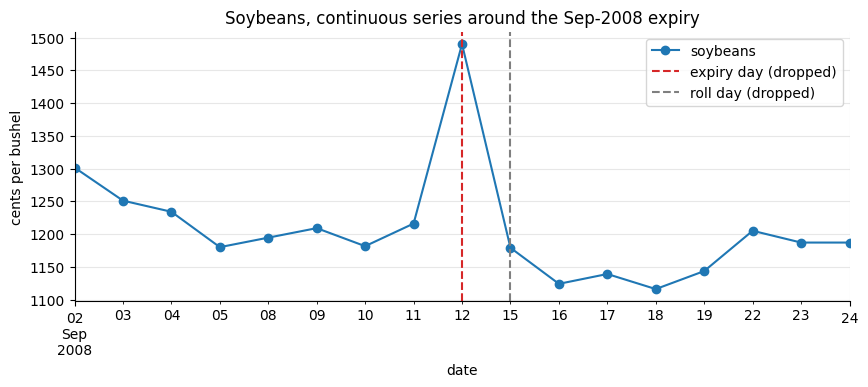

In [4]:
# Example of a bad expiry-day print: soybeans, September 2008 contract
window = closes["soybeans"].loc["2008-09-02":"2008-09-24"]
ax = window.plot(marker="o", title="Soybeans, continuous series around the Sep-2008 expiry", figsize=(10, 3.5))
ax.axvline(pd.Timestamp("2008-09-12"), color="tab:red", ls="--", label="expiry day (dropped)")
ax.axvline(pd.Timestamp("2008-09-15"), color="tab:gray", ls="--", label="roll day (dropped)")
ax.set_ylabel("cents per bushel"); ax.legend(); plt.show()

### 1.2 Price levels

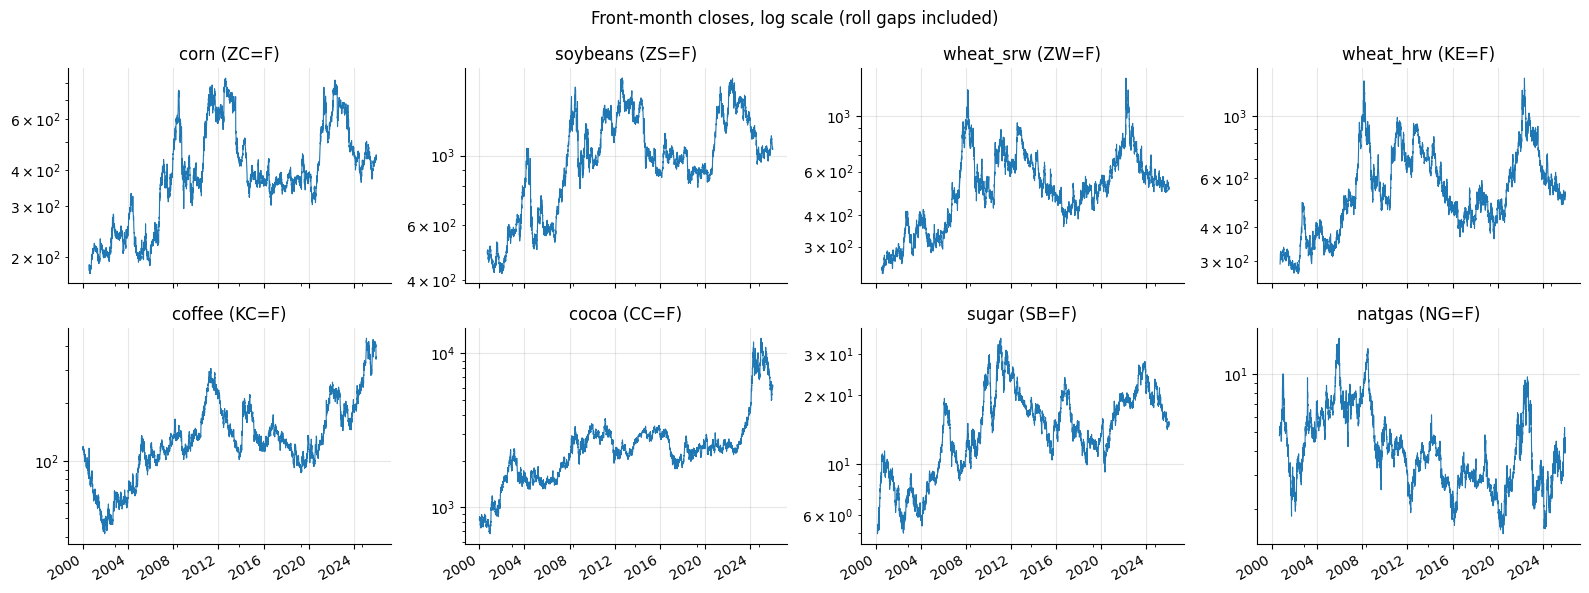

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True)
for ax, name in zip(axes.flat, NAMES):
    closes[name].dropna().plot(ax=ax, lw=0.8)
    ax.set_yscale("log"); ax.set_title(f"{name} ({COMMODITIES[name]['ticker']})"); ax.set_xlabel("")
fig.suptitle("Front-month closes, log scale (roll gaps included)"); fig.tight_layout(); plt.show()

Visible episodes: the 2007-2008 commodity boom and crash, the 2010-2012 grain rally (Russian
export ban, US drought 2012), the 2022 spike (war in Ukraine), cocoa's 2023-2024 tripling
(West African crop failure), the 2005 and 2008 gas peaks.

### 1.3 Moments and normality

Stylized facts of financial returns (Cont, 2001) and of agricultural futures:

1. **Fat tails**: excess kurtosis well above 0, normality rejected.
2. **Skewness**: for commodities, scarcity creates price spikes, so returns tend to be
   **positively skewed** (competitive storage model, Deaton and Laroque, 1992), unlike equities.
3. **Aggregational Gaussianity**: the distribution gets closer to normal as the horizon grows
   (kurtosis falls from daily to weekly to monthly).
4. Natural gas is the most volatile market (around 50 % a year), grains around 25 to 30 %.

`skew` is the 3rd standardized moment (normal: 0), `ex_kurt` the 4th minus 3 (normal: 0),
`jb_pvalue` the Jarque-Bera test of both being 0.

In [6]:
print("Daily log returns")
describe.moments(returns[NAMES], 252)

Daily log returns


,n_obs,mean_ann,vol_ann,skew,ex_kurt,min,max,jb_pvalue
corn,6114.000,0.011,0.263,-0.030,2.379,-0.104,0.086,0.000
soybeans,6008.000,0.115,0.228,-0.238,2.702,-0.086,0.076,0.000
wheat_srw,6126.000,-0.077,0.316,0.253,3.413,-0.113,0.197,0.000
wheat_hrw,6105.000,-0.025,0.291,0.069,1.414,-0.090,0.081,0.000
coffee,6256.000,-0.009,0.336,0.207,2.507,-0.113,0.166,0.000
cocoa,6258.000,0.112,0.331,-0.233,4.192,-0.192,0.128,0.000
sugar,6273.000,0.014,0.308,-0.170,2.017,-0.124,0.105,0.000
natgas,5754.000,-0.234,0.546,0.083,3.339,-0.181,0.324,0.000


In [7]:
print("Weekly log returns (Friday to Friday)")
describe.moments(weekly_ret, 52)

Weekly log returns (Friday to Friday)


,n_obs,mean_ann,vol_ann,skew,ex_kurt,min,max,jb_pvalue
corn,1326.000,0.010,0.263,-0.179,2.168,-0.179,0.149,0.000
soybeans,1320.000,0.108,0.225,-0.378,2.379,-0.167,0.132,0.000
wheat_srw,1328.000,-0.073,0.309,0.959,11.589,-0.212,0.469,0.000
wheat_hrw,1320.000,-0.024,0.287,0.363,2.936,-0.151,0.303,0.000
coffee,1357.000,-0.009,0.308,0.324,1.210,-0.126,0.256,0.000
cocoa,1356.000,0.107,0.330,-0.007,2.652,-0.234,0.225,0.000
sugar,1349.000,0.014,0.301,-0.068,1.080,-0.192,0.176,0.000
natgas,1323.000,-0.210,0.508,0.092,2.052,-0.274,0.450,0.000


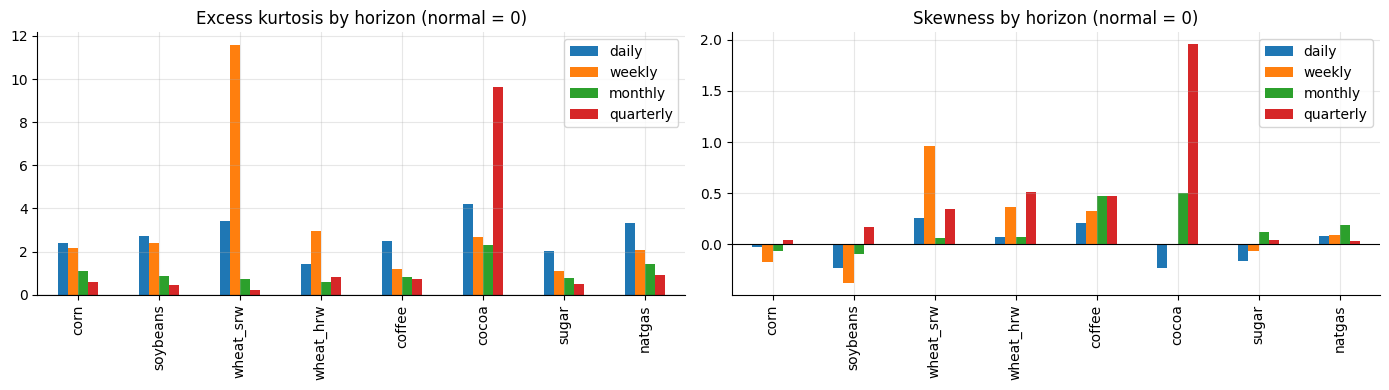

,daily,weekly,monthly,quarterly
corn,2.379,2.168,1.074,0.597
soybeans,2.702,2.379,0.876,0.428
wheat_srw,3.413,11.589,0.731,0.193
wheat_hrw,1.414,2.936,0.576,0.841
coffee,2.507,1.210,0.827,0.734
cocoa,4.192,2.652,2.320,9.645
sugar,2.017,1.080,0.779,0.485
natgas,3.339,2.052,1.404,0.900


In [8]:
horizons = {"daily": returns[NAMES], "weekly": weekly_ret,
            "monthly": describe.aggregate(returns[NAMES], "ME"),
            "quarterly": describe.aggregate(returns[NAMES], "QE")}
kurt = pd.DataFrame({h: r.apply(lambda x: stats.kurtosis(x.dropna())) for h, r in horizons.items()})
skew = pd.DataFrame({h: r.apply(lambda x: stats.skew(x.dropna())) for h, r in horizons.items()})

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
kurt.plot.bar(ax=axes[0], title="Excess kurtosis by horizon (normal = 0)")
skew.plot.bar(ax=axes[1], title="Skewness by horizon (normal = 0)")
for ax in axes: ax.axhline(0, color="black", lw=0.8)
fig.tight_layout(); plt.show()
kurt

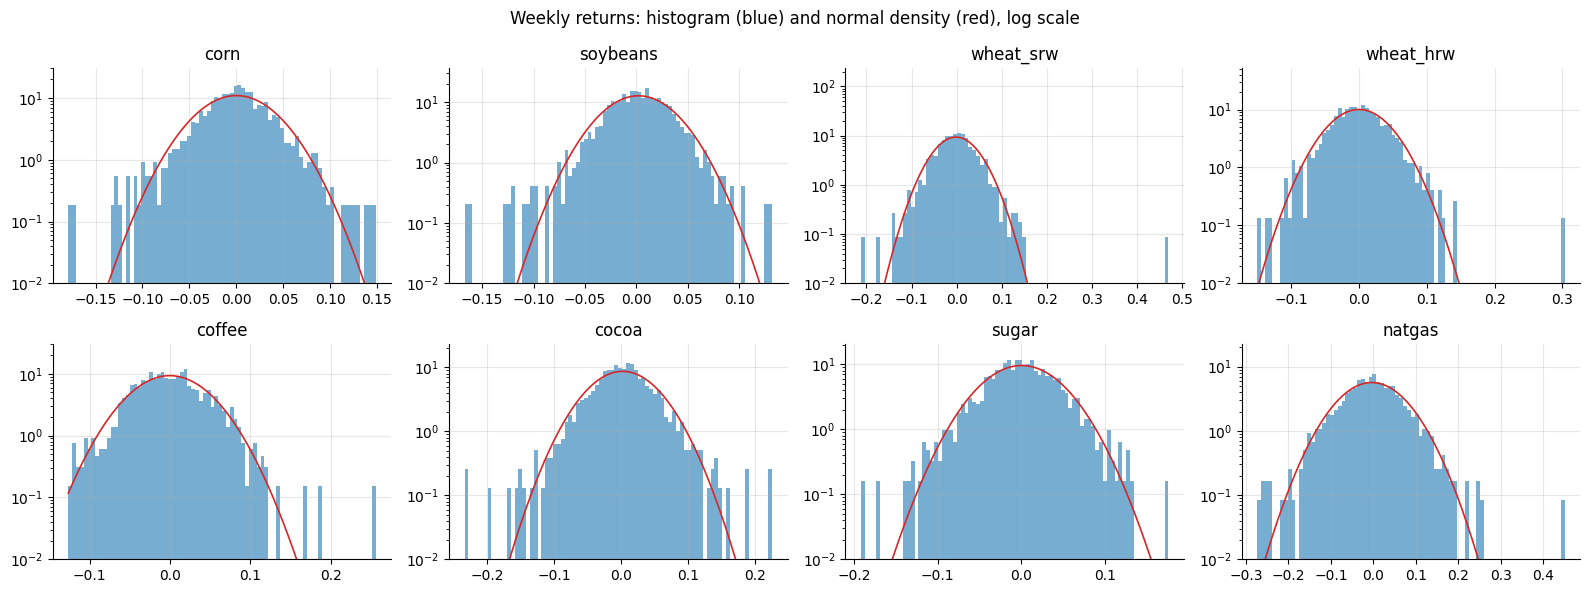

In [9]:
# Histograms of weekly returns with the normal law of same mean and variance, log scale to see the tails
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, name in zip(axes.flat, NAMES):
    x = weekly_ret[name].dropna()
    ax.hist(x, bins=80, density=True, alpha=0.6)
    grid = np.linspace(x.min(), x.max(), 300)
    ax.plot(grid, stats.norm.pdf(grid, x.mean(), x.std()), color="tab:red", lw=1.2)
    ax.set_yscale("log"); ax.set_ylim(bottom=0.01); ax.set_title(name)
fig.suptitle("Weekly returns: histogram (blue) and normal density (red), log scale"); fig.tight_layout(); plt.show()

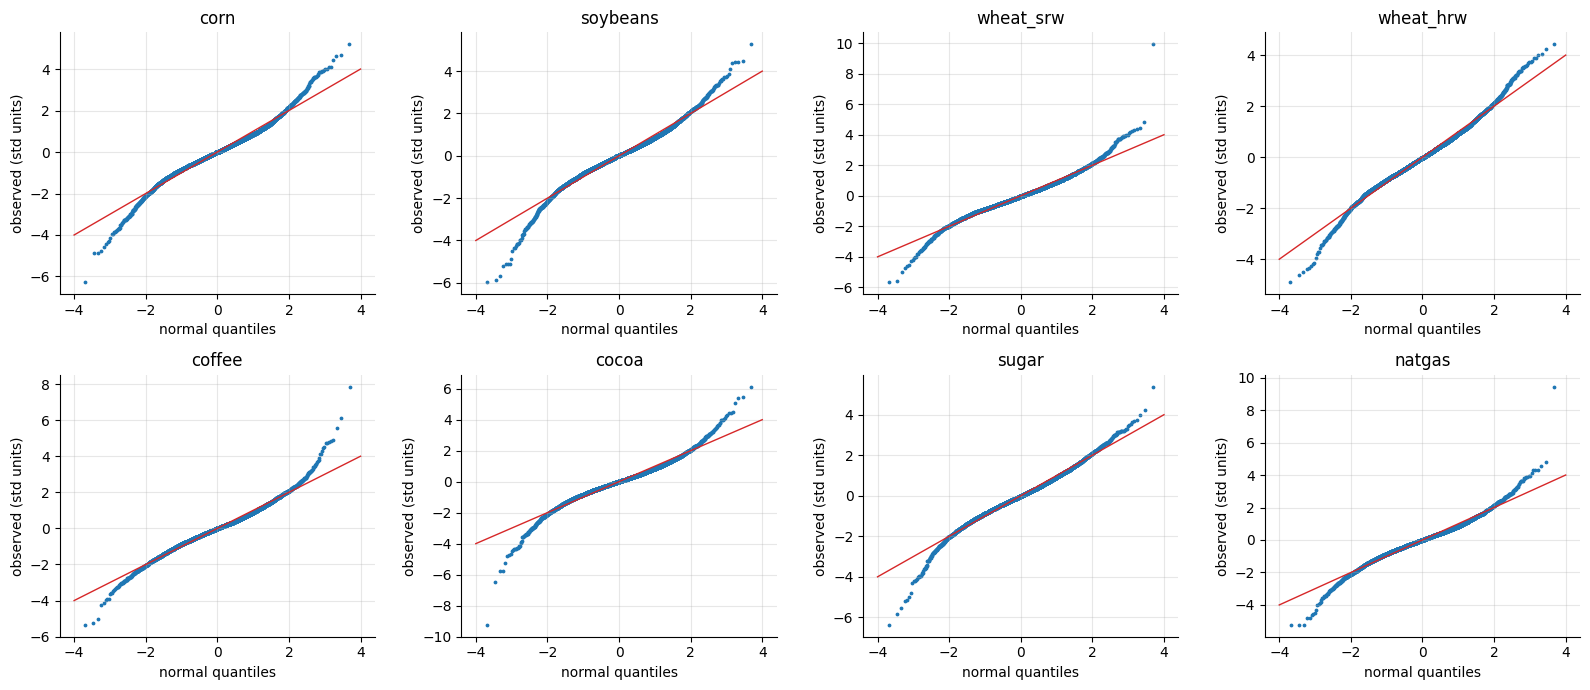

In [10]:
# QQ plots of daily returns: points above the line on the right / below on the left = fat tails
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, name in zip(axes.flat, NAMES):
    x = returns[name].dropna()
    (osm, osr), _ = stats.probplot((x - x.mean()) / x.std(), dist="norm")
    ax.scatter(osm, osr, s=3)
    ax.plot([-4, 4], [-4, 4], color="tab:red", lw=1)
    ax.set_title(name); ax.set_xlabel("normal quantiles"); ax.set_ylabel("observed (std units)")
fig.tight_layout(); plt.show()

In [11]:
print("Share of daily returns beyond k standard deviations, versus the normal law")
describe.tail_frequency(returns[NAMES])

Share of daily returns beyond k standard deviations, versus the normal law


,|z|>2,|z|>3,|z|>4
corn,0.056,0.014,0.002
soybeans,0.055,0.014,0.004
wheat_srw,0.049,0.011,0.003
wheat_hrw,0.050,0.011,0.002
coffee,0.053,0.010,0.003
cocoa,0.050,0.014,0.005
sugar,0.051,0.010,0.003
natgas,0.054,0.012,0.003
normal,0.046,0.003,0.000


**Reading.**

* Normality is rejected everywhere (Jarque-Bera p-values are 0). Daily excess kurtosis lies
  between 1.4 (HRW wheat) and 4.2 (cocoa). Returns beyond 3 standard deviations happen
  4 to 5 times more often than under the normal law, beyond 4 standard deviations 30 to 70 times more.
* Kurtosis falls with the horizon (aggregational Gaussianity), but monthly returns are still not normal
  (except HRW wheat, JB p = 0.11). Two exceptions come from single episodes: weekly SRW wheat
  (excess kurtosis 11.6) from the week ending 4 March 2022, start of the war in Ukraine (+0.47 in log, +60 %),
  and quarterly cocoa (9.6) from the first quarter of 2024 (+0.93 in log, the price multiplied by 2.5).
* Skewness is small and its sign is mixed: positive for coffee, the wheats and natural gas,
  negative for soybeans and cocoa. The positive skew predicted by the storage model shows up
  only partially at short horizons; at the monthly horizon coffee and cocoa are clearly positive (about +0.5).
* The extreme days that remain after cleaning are real events: gas on 24 February 2003 (cold spike, +32 %),
  coffee on 18 July 2000 (Brazilian frost), wheat in March 2022, cocoa in May 2024.

### 1.4 Dependence over time

5. **No linear autocorrelation of returns** (otherwise trivial trading profits).
6. **Volatility clustering**: absolute returns are strongly and persistently autocorrelated.

The Ljung-Box test checks the first 10 autocorrelations jointly (p < 0.05: significant).

In [12]:
print("Daily returns")
describe.autocorrelation_table(returns[NAMES])

Daily returns


,acf1 r,LB(10) p r,acf1 |r|,LB(10) p |r|
corn,0.022,0.259,0.163,0.000
soybeans,-0.001,0.638,0.138,0.000
wheat_srw,0.008,0.543,0.149,0.000
wheat_hrw,0.034,0.039,0.144,0.000
coffee,-0.030,0.128,0.085,0.000
cocoa,0.008,0.088,0.146,0.000
sugar,0.005,0.004,0.092,0.000
natgas,-0.054,0.000,0.126,0.000


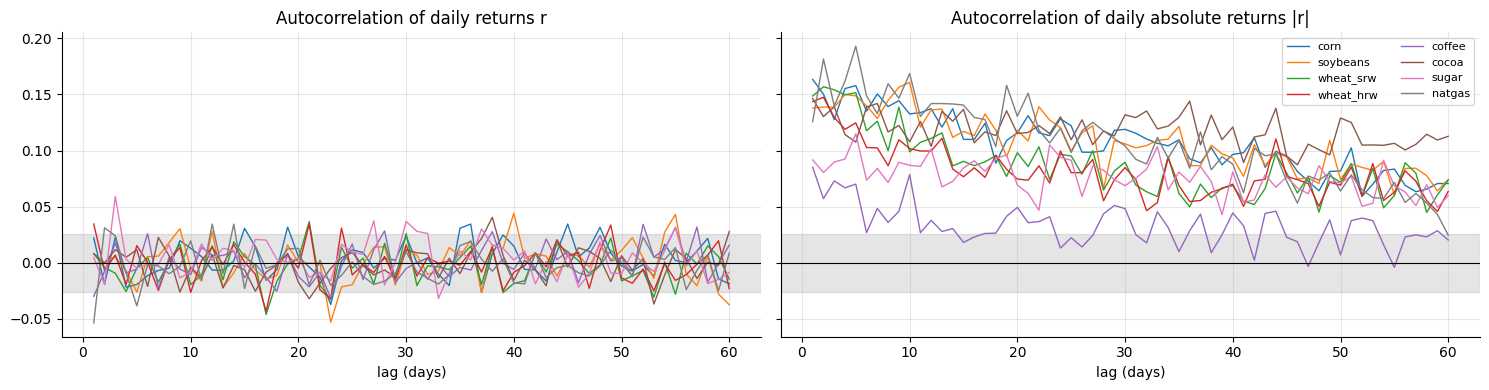

In [13]:
lags = 60
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for name in NAMES:
    axes[0].plot(describe.acf(returns[name], lags), lw=1, label=name)
    axes[1].plot(describe.acf(returns[name].abs(), lags), lw=1, label=name)
band = 1.96 / np.sqrt(returns.notna().sum().min())
for ax, title in zip(axes, ["returns r", "absolute returns |r|"]):
    ax.axhspan(-band, band, color="grey", alpha=0.2)
    ax.axhline(0, color="black", lw=0.8); ax.set_title(f"Autocorrelation of daily {title}"); ax.set_xlabel("lag (days)")
axes[1].legend(ncol=2, fontsize=8); fig.tight_layout(); plt.show()

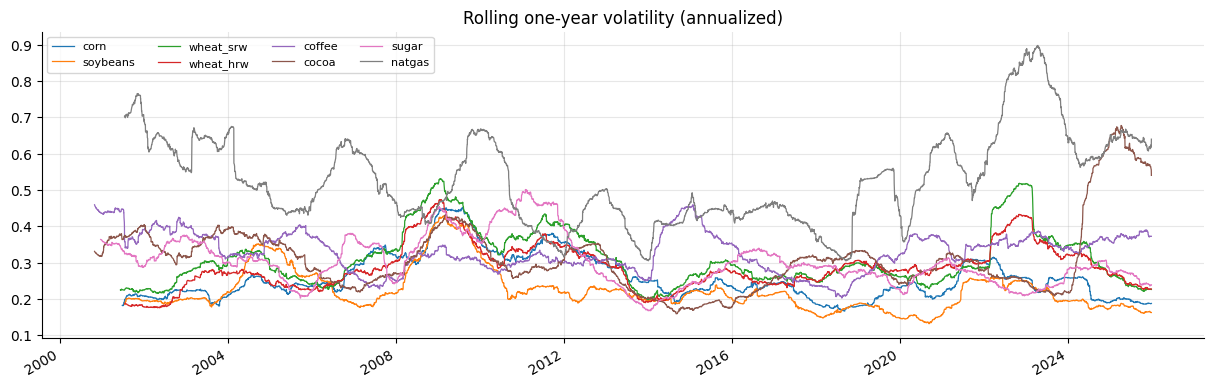

In [14]:
fig, ax = plt.subplots(figsize=(15, 4.5))
(returns[NAMES].rolling(252, min_periods=200).std() * np.sqrt(252)).plot(ax=ax, lw=0.9)
ax.set_title("Rolling one-year volatility (annualized)"); ax.set_xlabel(""); ax.legend(ncol=4, fontsize=8)
plt.show()

**Reading.** Return autocorrelations are tiny (|acf1| below 0.06) and inside or close to the
confidence band. With 6,000 observations even tiny values become significant: Ljung-Box rejects
for natural gas, sugar and HRW wheat, but autocorrelations of 0.05 have no economic size. Absolute returns have first-order autocorrelations of 0.08 to 0.16 that decay
slowly over 60 days: volatility clusters, as in every financial market. The rolling volatility
shows the same thing in calendar time (2008, 2012 for grains, 2022, 2024 for cocoa).

### 1.5 Seasonality of volatility

7. For grains, volatility peaks in **June and July**, when the US crop is most exposed to weather
   and the market learns the size of the harvest, and is lowest in winter (Anderson, 1985;
   Fackler, 1986). This is the fact that matters most for us: it says *when* weather should move prices.
8. Natural gas volatility peaks in **winter** (heating demand, low storage at the end of winter).
9. For arabica coffee, the Brazilian frost season (June to August) should stand out.

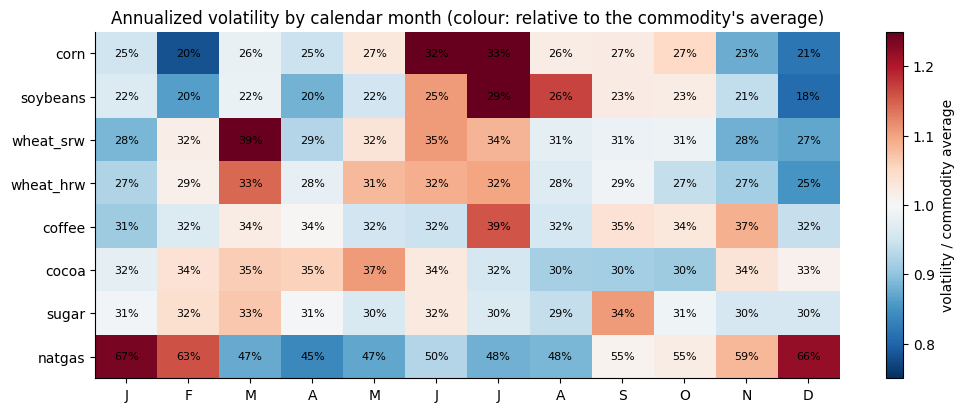

In [15]:
vm = describe.vol_by_month(returns[NAMES])
relative = vm.div(vm.mean(axis=1), axis=0)  # 1 = the commodity's average volatility

fig, ax = plt.subplots(figsize=(12, 4.5))
im = ax.imshow(relative.values, cmap="RdBu_r", vmin=0.75, vmax=1.25, aspect="auto")
ax.set_xticks(range(12), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_yticks(range(len(NAMES)), NAMES); ax.grid(False)
for i in range(len(NAMES)):
    for j in range(12):
        ax.text(j, i, f"{vm.values[i, j]:.0%}", ha="center", va="center", fontsize=8)
fig.colorbar(im, label="volatility / commodity average")
ax.set_title("Annualized volatility by calendar month (colour: relative to the commodity's average)")
plt.show()

**Reading.** All three facts appear in our data:

* corn: 32 to 33 % in June and July against 20 to 21 % in February and December; soybeans peak
  in July (29 %) and bottom in December (18 %);
* natural gas: 63 to 67 % from December to February against 45 to 47 % in spring;
* coffee: its highest month is July (39 %), in the middle of the frost season;
* the wheats peak earlier (March, around the end of dormancy and the US Plains spring);
  cocoa and sugar show no clear pattern, which is consistent with crops harvested over most of the year.

### 1.6 Leverage effect

10. In equities, volatility rises more after a fall (leverage effect). In commodities the opposite
    is expected: a price **spike** signals scarcity and raises volatility (*inverse leverage* or
    inventory effect, Carpantier, 2010).

Below: correlation between this week's return and next week's realized volatility, and the mean
next-week volatility after the 10 % worst and the 10 % best weeks.

In [16]:
describe.leverage_table(weekly).loc[NAMES]

,"corr(r, next rv)",next rv after down,next rv after up
corn,-0.008,0.280,0.288
soybeans,-0.003,0.248,0.252
wheat_srw,0.101,0.318,0.359
wheat_hrw,0.066,0.288,0.320
coffee,0.166,0.281,0.356
cocoa,0.008,0.342,0.357
sugar,-0.011,0.329,0.302
natgas,0.088,0.552,0.647


**Reading.** Inverse leverage is clear for coffee (next-week volatility 36 % after a strong rise
against 28 % after a strong fall), natural gas and the two wheats. Corn, soybeans, cocoa and sugar
are neutral. No commodity shows an equity-style leverage effect.

### 1.7 Correlations

11. Low correlation across commodity groups, high within a group (Gorton and Rouwenhorst, 2006;
    Erb and Harvey, 2006): the grains move together, softs and energy are largely independent.
12. Correlations rose sharply around 2008 (financialization, Tang and Xiong, 2012) and fell back after.

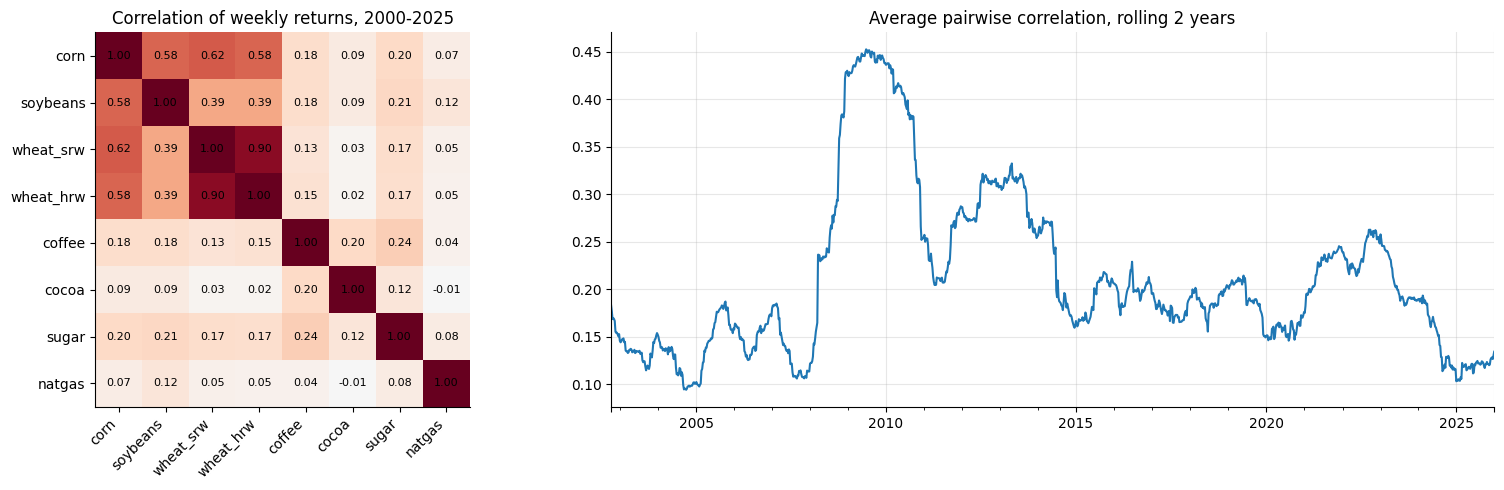

In [17]:
corr = weekly_ret.corr()
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1.4]})
im = axes[0].imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(NAMES)), NAMES, rotation=45, ha="right"); axes[0].set_yticks(range(len(NAMES)), NAMES)
axes[0].grid(False)
for i in range(len(NAMES)):
    for j in range(len(NAMES)):
        axes[0].text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
axes[0].set_title("Correlation of weekly returns, 2000-2025")
describe.rolling_mean_correlation(weekly_ret.dropna()).plot(ax=axes[1])
axes[1].set_title("Average pairwise correlation, rolling 2 years"); axes[1].set_xlabel("")
fig.tight_layout(); plt.show()

**Reading.** The two wheats correlate at 0.90, corn with the wheats around 0.6, corn with soybeans
0.58. Coffee, cocoa and sugar correlate at 0 to 0.25 with everything, natural gas at about 0 to 0.1.
The average pairwise correlation goes from about 0.13 before 2007 to 0.44 in 2009, then back down.

This matters for the project: the eight markets carry largely independent risk, so weather in
eight different places can in principle explain different things.

## 2. Production weights

Weather is averaged over each zone with the share of production of each 0.5 degree cell
(MapSPAM 2010; population of 31 large metro areas for natural gas). Three checks:
the zone totals against official statistics, the main regions, and how concentrated the weights are.

### 2.1 Totals and main regions

In [18]:
# Production in MapSPAM (tonnes, 2010) by zone, and the four largest regions of each zone
top = (regions.sort_values("share", ascending=False).groupby(["commodity", "zone"], sort=False)
       .head(4).assign(region=lambda d: d["adm1"] + " " + (100 * d["share"]).round(0).astype(int).astype(str) + "%")
       .groupby(["commodity", "zone"])["region"].apply(", ".join))
totals = regions.groupby(["commodity", "zone"])["mass"].sum() / 1e6
table = pd.DataFrame({"production 2010 (Mt)": totals, "largest regions": top})
table.loc[[(c, z) for c in NAMES for z in COMMODITIES[c]["zones"] if (c, z) in table.index]]

production 2010 (Mt)                                    largest regions
commodity zone                                                                              
corn      US                      320.877  Iowa 18%, Illinois 16%, Nebraska 12%, Minnesot...
soybeans  US                       88.739  Iowa 15%, Illinois 14%, Minnesota 9%, Nebraska 8%
          BRA                      66.971  Mato Grosso 29%, Parana 19%, Rio Grande Do Sul...
          ARG                      44.336  Buenos Aires 30%, Cordoba 28%, Santa Fe 21%, E...
wheat_srw US                        7.828  Ohio 20%, Michigan 16%, Illinois 14%, North Ca...
          EU                       77.126  Centre 7%, Picardie 6%, Bayern 5%, Niedersachs...
          BLACK_SEA                53.998  Krasnodarskiy Kray 12%, Stavropolskiy Kray 11%...
wheat_hrw US                       22.402  Kansas 44%, South Dakota 14%, Colorado 12%, Ok...
coffee    BRA                       1.615  Minas Gerais 50%, Espirito Santo 24%, Sao Paul...
          COL                       0.491   Antioquia 16%, Huila 14%, Caldas 12%, Tolima 11%
cocoa     WAF                       2.657  Western 15%, Bas Sassandra 8%, Haut-sassandra ...
sugar     BRA                     711.471  Sao Paulo 58%, Minas Gerais 9%, Parana 7%, Goi...
          IND                     306.572  Uttar Pradesh 39%, Maharashtra 30%, Tamil Nadu...
          THA                      77.192  Northeastern 47%, Central 27%, Northern 26%, S...

In [19]:
# Country split inside the multi-country zones
country = regions.groupby(["commodity", "zone", "iso3"])["mass"].sum()
share = (country / country.groupby(["commodity", "zone"]).transform("sum")).rename("share")
share[share.index.get_level_values("zone").isin(["WAF", "EU", "BLACK_SEA"])].to_frame()

share
commodity zone      iso3       
cocoa     WAF       CIV   0.506
                    CMR   0.093
                    GHA   0.257
                    NGA   0.145
wheat_srw BLACK_SEA RUS   0.629
                    UKR   0.371
          EU        DEU   0.312
                    FRA   0.486
                    POL   0.124
                    ROU   0.078

**Comparison with official 2010 figures (approximate, USDA and FAOSTAT):** US corn 316 Mt (MapSPAM 321),
US soybeans 91 Mt (89), Brazilian sugarcane 717 Mt (712), Indian sugarcane 292 Mt (307),
Ivory Coast cocoa about 1.3 Mt (1.34), Ghana about 0.6 Mt (0.68), France wheat 38 Mt (37.5).
The ranking of regions is the expected one: Iowa, Illinois, Nebraska for corn; Mato Grosso and
Parana for Brazilian soybeans; Buenos Aires, Cordoba, Santa Fe for Argentina; Minas Gerais for
coffee; Sao Paulo (58 %) for Brazilian cane; Uttar Pradesh and Maharashtra for Indian cane; Kansas for HRW.

**Limits.**

* MapSPAM does not separate wheat classes. The "HRW" zone contains South Dakota (14 %), which grows
  mostly spring wheat, and the "SRW" US zone contains Michigan (16 %), which grows a lot of soft white wheat.
* Espirito Santo gets 24 % of Brazilian arabica, which looks high: the state mainly grows robusta (conilon).
* The map is a 2010 snapshot: Brazilian soybeans have since moved north (Mato Grosso, Matopiba),
  and West African cocoa has moved west within Ivory Coast.

### 2.2 Concentration

In [20]:
rows = {}
for (com, zone), g in weights.groupby(["commodity", "zone"]):
    w = g["weight"].sort_values(ascending=False)
    rows[(com, zone)] = {"cells": len(w),
                         "effective cells (1 / sum w2)": 1 / (w ** 2).sum(),
                         "cells for 50 % of weight": int((w.cumsum() < 0.5).sum() + 1),
                         "cells for 90 % of weight": int((w.cumsum() < 0.9).sum() + 1),
                         "largest cell": w.iloc[0]}
pd.DataFrame(rows).T.loc[[(c, z) for c in NAMES for z in COMMODITIES[c]["zones"]]]

cells  effective cells (1 / sum w2)  cells for 50 % of weight  cells for 90 % of weight  largest cell
corn      US        2179.000                       468.110                   162.000                   552.000         0.005
soybeans  US        1594.000                       510.825                   185.000                   529.000         0.004
          BRA       1228.000                       315.333                   112.000                   406.000         0.009
          ARG        570.000                       158.218                    56.000                   187.000         0.014
wheat_srw US         409.000                       145.191                    53.000                   196.000         0.019
          EU         831.000                       377.658                   140.000                   442.000         0.008
          BLACK_SEA 1017.000                       449.027                   180.000                   544.000         0.007
wheat_hrw US         640.000                       201.081                    70.000                   237.000         0.011
coffee    BRA       1151.000                        77.515                    27.000                   145.000         0.033
          COL        174.000                        31.166                    12.000                    51.000         0.102
cocoa     WAF        319.000                       104.943                    37.000                   126.000         0.026
sugar     BRA       1885.000                       120.817                    43.000                   185.000         0.022
          IND        959.000                       106.662                    40.000                   183.000         0.035
          THA        229.000                        85.144                    34.000                    86.000         0.033
natgas    US          31.000                        19.753                     8.000                    25.000         0.132

`effective cells` is the number of equally weighted cells that would give the same concentration
(inverse Herfindahl). Most zones rest on a few hundred effective cells, i.e. tens of thousands of km2:
the zone average is a regional signal and smooths out local events (see the 2021 coffee frost below).
Natural gas rests on 31 cities, about 20 effective cells; the largest (New York) carries 13 % of the weight.
Arabica is the most concentrated crop zone: 27 cells (out of 1,151) carry half of the Brazilian weight.

### 2.3 Maps

Grey: land cells of the weather grid. Colour: weight of each cell in its zone, **log scale**
(otherwise only the top cells are visible). Each map is zoomed on the cells that carry weight.

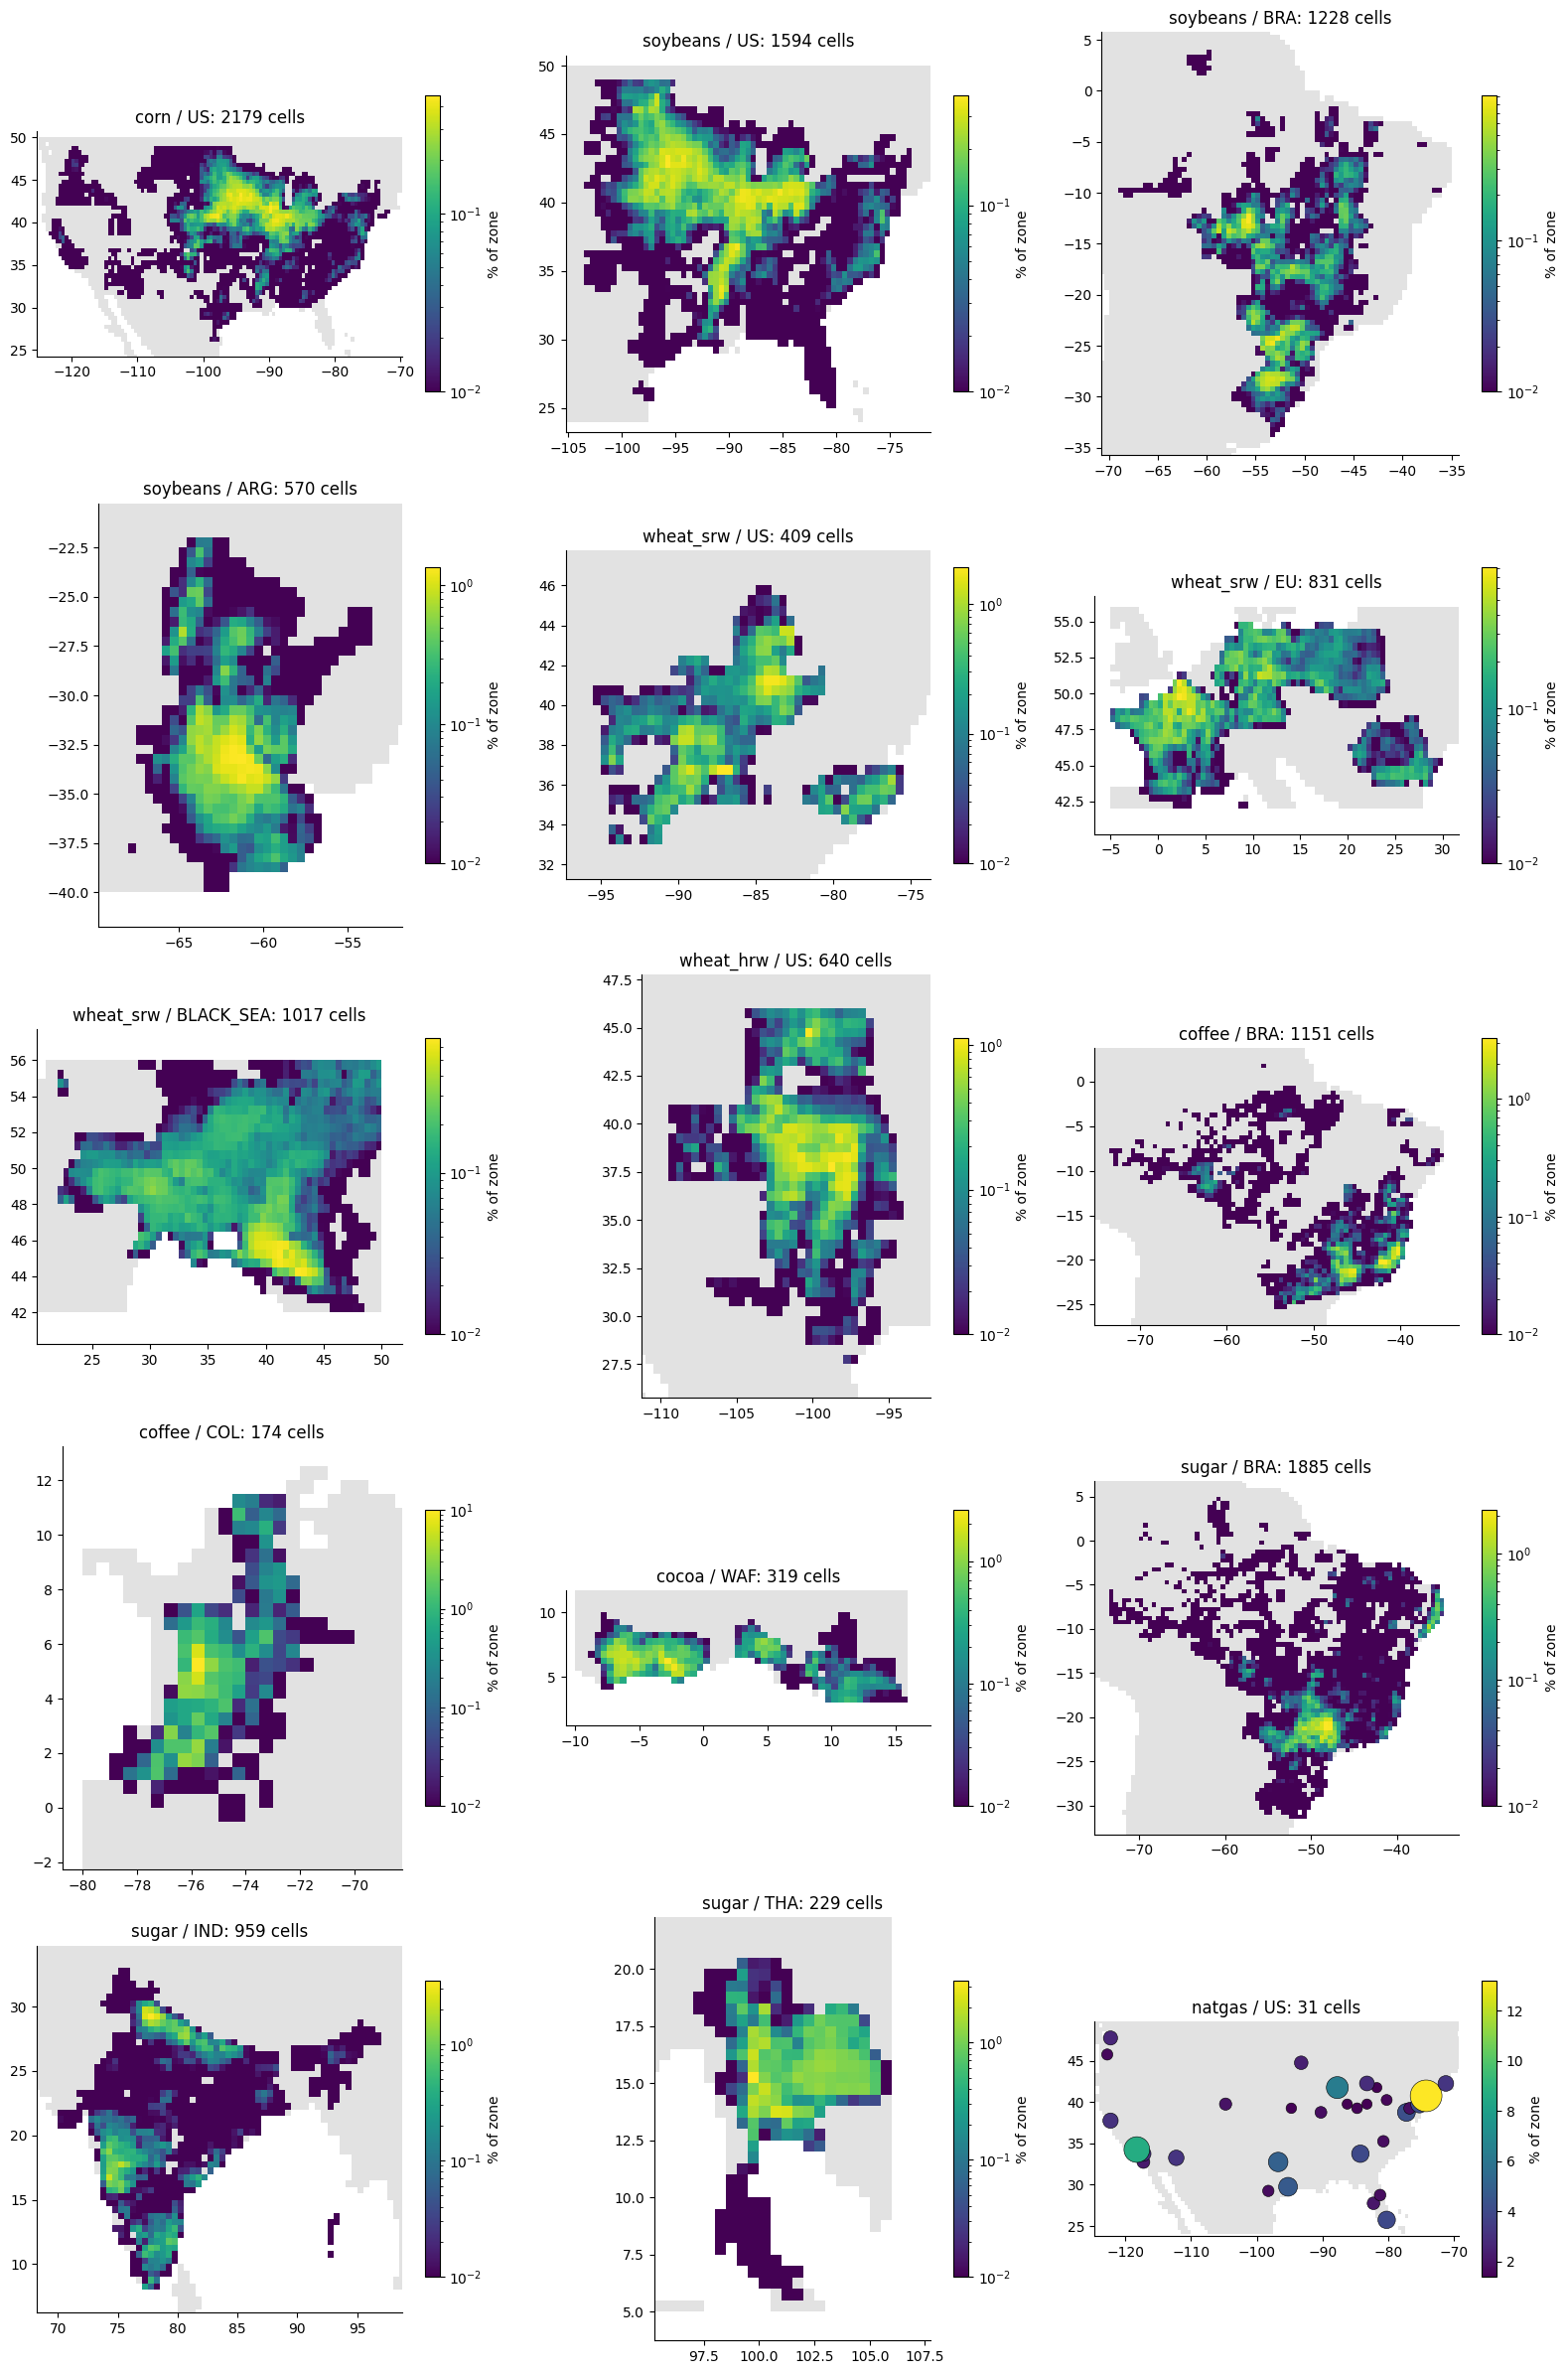

In [21]:
zones = [(c, z) for c in NAMES for z in COMMODITIES[c]["zones"]]

def to_grid(lat, lon, value):
    # Cells (lat, lon, value) to a 2-D array on the regular 0.5 degree grid, NaN elsewhere
    table = pd.DataFrame({"lat": lat, "lon": lon, "v": value}).pivot_table(index="lat", columns="lon", values="v")
    lats = np.arange(table.index.min(), table.index.max() + 0.25, 0.5)
    lons = np.arange(table.columns.min(), table.columns.max() + 0.25, 0.5)
    table = table.reindex(index=lats, columns=lons, method="nearest", tolerance=0.1)
    return table.columns.values, table.index.values, table.values

fig, axes = plt.subplots(5, 3, figsize=(16, 24))
for ax, (com, zone) in zip(axes.flat, zones):
    g = weights[(weights["commodity"] == com) & (weights["zone"] == zone)]
    lm = land[land["box"] == g["box"].iloc[0]]
    # Background: land cells of the download box, drawn as real 0.5 degree squares
    x, y, v = to_grid(lm["lat"], lm["lon"], np.ones(len(lm)))
    ax.pcolormesh(x, y, v, cmap="Greys", vmin=0, vmax=5, shading="nearest")
    pct = 100 * g["weight"]
    if com == "natgas":
        # 31 cities only: circles sized by population share
        sc = ax.scatter(g["lon"], g["lat"], s=40 * pct, c=pct, cmap="viridis", edgecolors="black", linewidths=0.4)
    else:
        # Weight of each cell in % of the zone, log scale (cells below 0.01 % get the darkest colour)
        x, y, v = to_grid(g["lat"], g["lon"], pct)
        sc = ax.pcolormesh(x, y, v, cmap="viridis", shading="nearest",
                           norm=LogNorm(vmin=0.01, vmax=pct.max()))
    pad = 2
    ax.set_xlim(g["lon"].min() - pad, g["lon"].max() + pad); ax.set_ylim(g["lat"].min() - pad, g["lat"].max() + pad)
    ax.set_aspect(1 / np.cos(np.radians(g["lat"].mean())))  # degrees of longitude shrink with latitude
    ax.set_title(f"{com} / {zone}: {len(g)} cells"); ax.grid(False)
    fig.colorbar(sc, ax=ax, shrink=0.7, label="% of zone")
fig.tight_layout(); plt.show()

## 3. Weather

### 3.1 What we have

NOAA CPC Global Unified: daily maximum and minimum temperature and precipitation interpolated from
weather stations onto a 0.5 degree grid (about 50 km), over land, from 1979. We use 1990 to 2025.
Known limits from NOAA's documentation:

* it is built from stations only: quality depends on station density, and NOAA states it is **poor
  over tropical Africa** (relevant for cocoa);
* precipitation switches in **2006** from a retrospective version (about 30,000 gauges) to a
  real-time version (about 17,000 gauges), so the station network changes over time (checked in 3.7).

`weather.py` computes daily variables per cell, averages them with the production weights and sums
or averages them by week (Friday to Friday). Variables: `tmax`, `tmin`, `tavg` (C), `precip`, `et0`
(evapotranspiration), `water_balance` (precip minus et0) in mm, `heavy_rain_days`, extreme degree days
`edd` above the crop's heat threshold, frost degree days `frost_dd`; for gas, heating and cooling
degree days `hdd`, `cdd` and `hard_freeze_days`.

In [22]:
counts = weather.groupby(level=["commodity", "zone"]).agg(["count"]).droplevel(1, axis=1)
summary = pd.DataFrame({
    "first week": weather.reset_index().groupby(["commodity", "zone"])["date"].min().dt.date,
    "last week": weather.reset_index().groupby(["commodity", "zone"])["date"].max().dt.date,
    "weeks": weather.groupby(level=["commodity", "zone"]).size(),
    "missing tmax": weather["tmax"].isna().groupby(level=["commodity", "zone"]).sum(),
    "missing precip": weather["precip"].isna().groupby(level=["commodity", "zone"]).sum(),
    "mean tmax (C)": weather["tmax"].groupby(level=["commodity", "zone"]).mean(),
    "mean tmin (C)": weather["tmin"].groupby(level=["commodity", "zone"]).mean(),
    "rain (mm/year)": weather["precip"].groupby(level=["commodity", "zone"]).mean() * 52.18,
})
summary.loc[zones]

first week   last week  weeks  missing tmax  missing precip  mean tmax (C)  mean tmin (C)  rain (mm/year)
commodity zone                                                                                                                
corn      US         1990-01-05  2026-01-02   1879             0               0         16.360          4.638         863.549
soybeans  US         1990-01-05  2026-01-02   1879             0               0         16.778          5.357         933.173
          BRA        1990-01-05  2026-01-02   1879             0               0         29.158         17.978        1503.763
          ARG        1990-01-05  2026-01-02   1879             0               0         23.983         11.676         965.197
wheat_srw US         1990-01-05  2026-01-02   1879             0               0         18.412          7.325        1082.024
          EU         1990-01-05  2026-01-02   1879             0               0         14.910          6.679         656.124
          BLACK_SEA  1990-01-05  2026-01-02   1879             0               0         13.841          5.080         523.324
wheat_hrw US         1990-01-05  2026-01-02   1879             0               0         19.640          5.109         616.273
coffee    BRA        1990-01-05  2026-01-02   1879             0               0         28.225         17.529        1219.049
          COL        1990-01-05  2026-01-02   1879             0               0         24.588         16.138        1767.971
cocoa     WAF        1990-01-05  2026-01-02   1879             0               0         31.200         22.906        1212.576
sugar     BRA        1990-01-05  2026-01-02   1879             0               0         29.488         18.867        1259.692
          IND        1990-01-05  2026-01-02   1879             0               0         31.625         19.959         924.721
          THA        1990-01-05  2026-01-02   1879             0               0         33.100         22.990        1331.575
natgas    US         1990-01-05  2026-01-02   1879             0               0         20.698         10.029         954.223

No missing week anywhere. Annual rainfall is in the expected ranges: about 860 mm for the Corn Belt,
620 mm for the Plains (HRW), 1,200 to 1,500 mm for central Brazil, 1,770 mm for the Colombian coffee
area, 520 mm for the Black Sea (semi-arid steppe).

### 3.2 Annual cycle

The first sanity check: each zone should show its known climate regime.

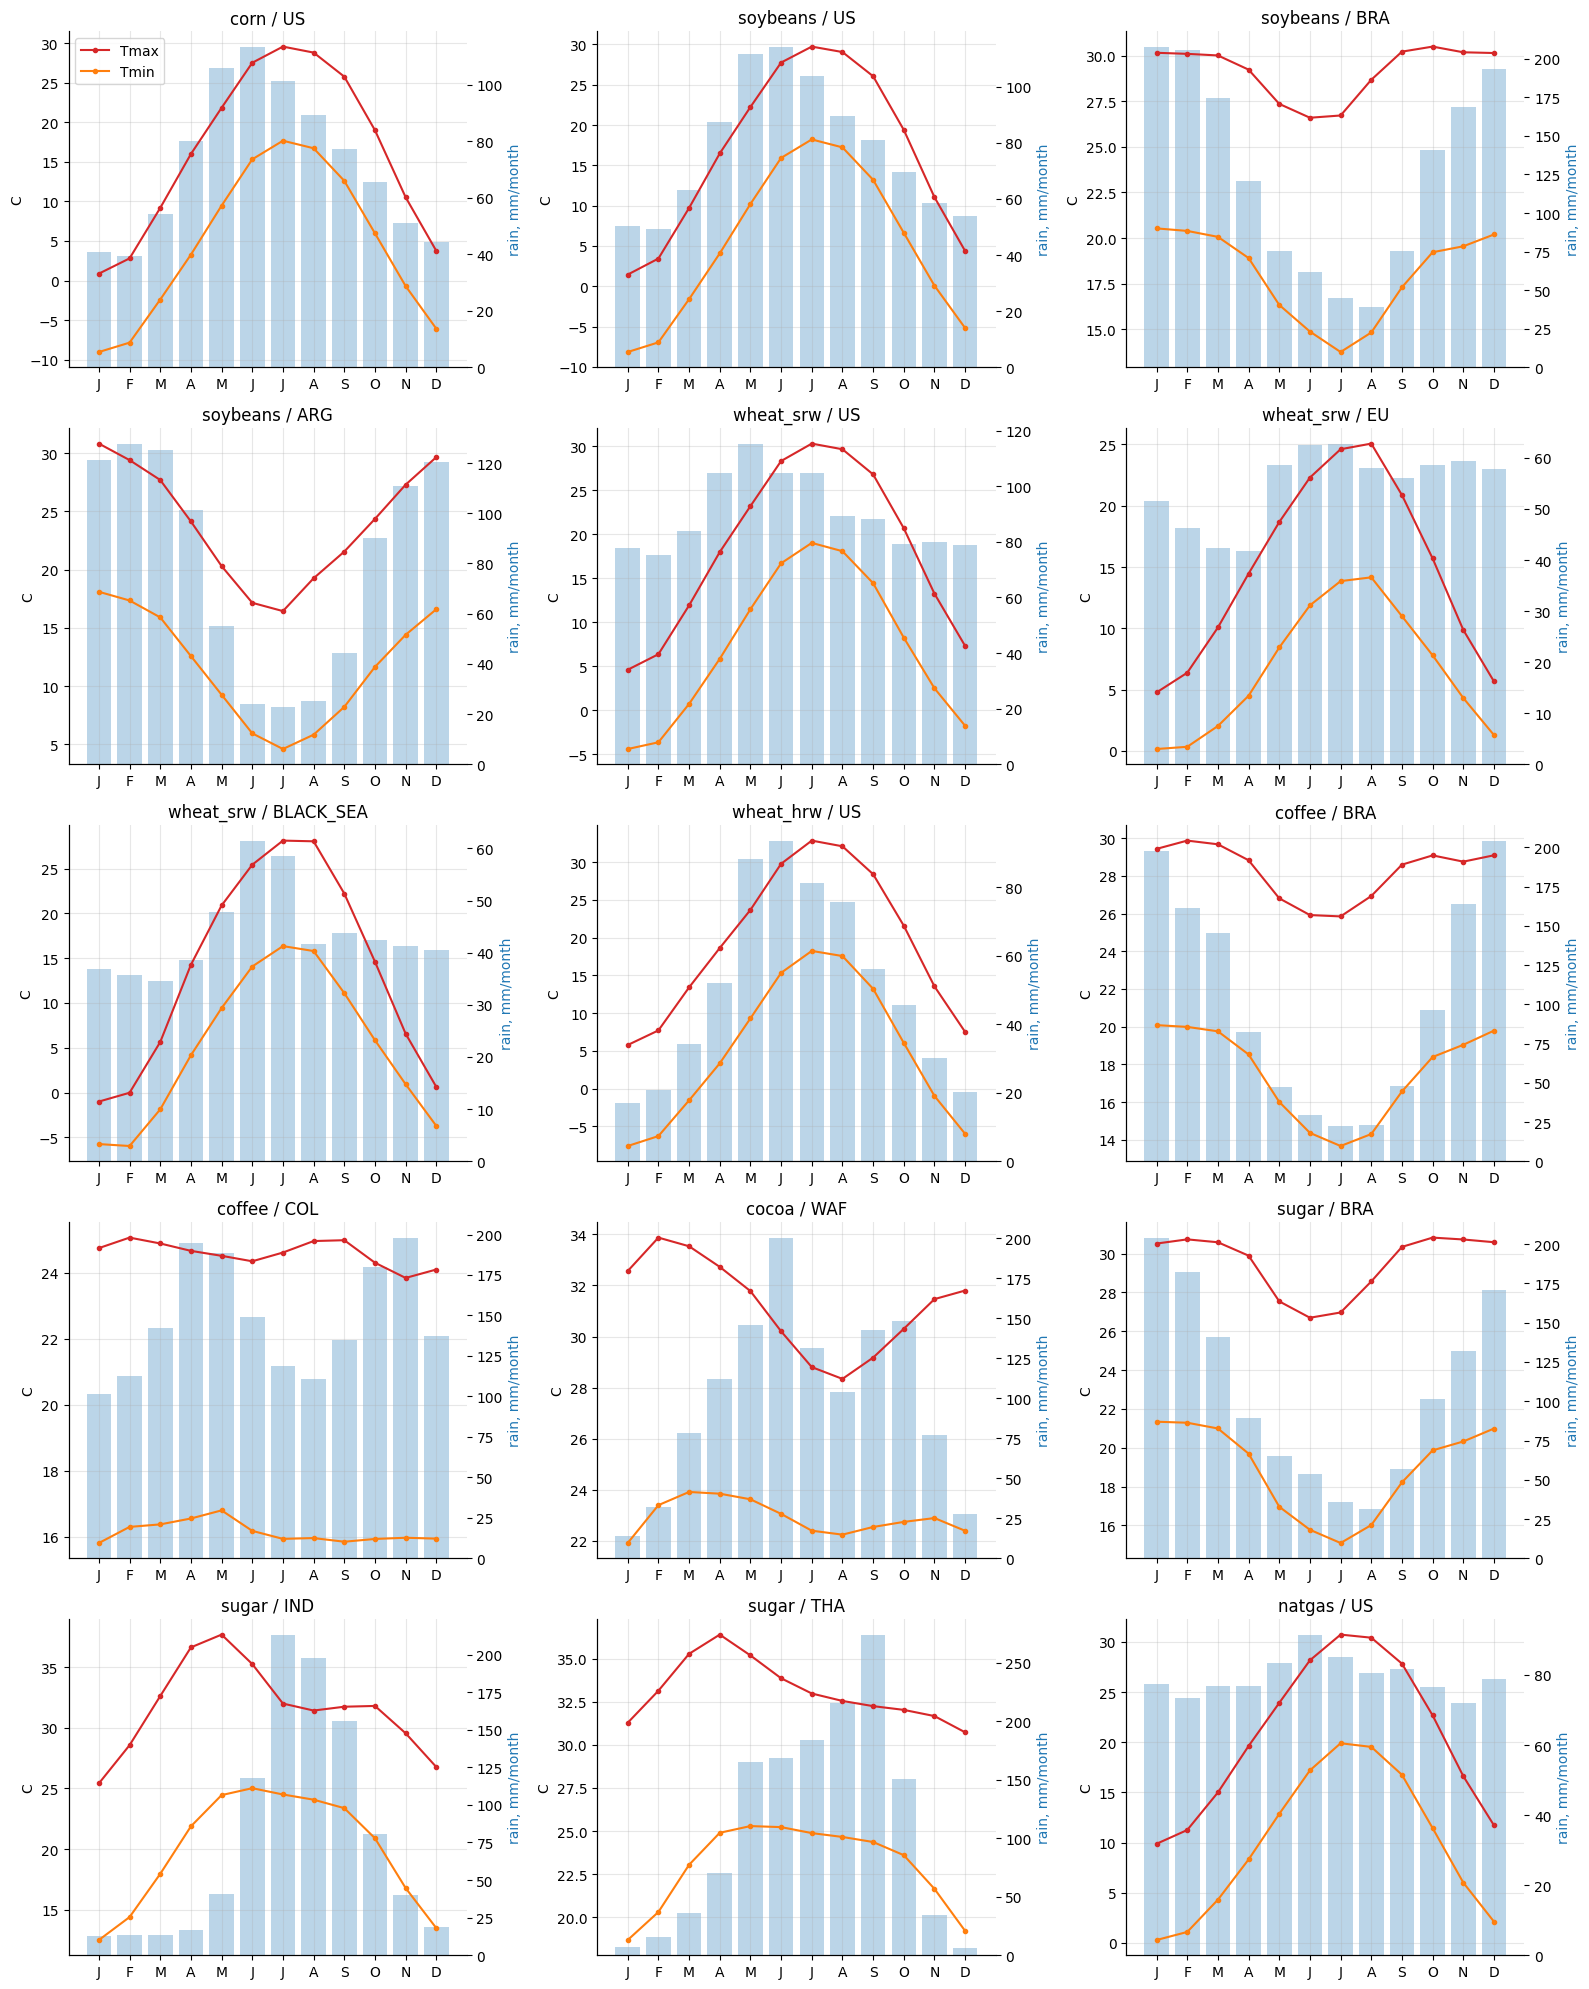

In [23]:
fig, axes = plt.subplots(5, 3, figsize=(16, 20))
months = np.arange(1, 13)
for ax, (com, zone) in zip(axes.flat, zones):
    z = weather.loc[(com, zone)]
    by_month = z.groupby(z.index.month)
    ax2 = ax.twinx()
    ax2.bar(months, by_month["precip"].mean() * 4.35, color="tab:blue", alpha=0.3)  # mm per month
    ax2.set_ylabel("rain, mm/month", color="tab:blue"); ax2.grid(False)
    ax.plot(months, by_month["tmax"].mean(), color="tab:red", marker="o", ms=3, label="Tmax")
    ax.plot(months, by_month["tmin"].mean(), color="tab:orange", marker="o", ms=3, label="Tmin")
    ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
    ax.set_xticks(months, list("JFMAMJJASOND")); ax.set_ylabel("C")
    ax.set_title(f"{com} / {zone}")
axes.flat[0].legend(loc="upper left")
fig.tight_layout(); plt.show()

**Reading.** Every regime is where it should be:

* northern hemisphere zones (US, Europe, Black Sea) peak in July, southern ones (Argentina) in January;
* Indian and Thai rain is concentrated in the June to September **monsoon**;
* central Brazil (coffee, soybeans, cane) has a **dry winter** from May to September, which is why
  the 2021 frost and droughts there happen in that window;
* West Africa shows its **two rainy seasons** (peaks in June and in September-October), with the dry
  Harmattan from December to February;
* Colombia also has two rainy seasons (April-May and October-November) and an almost flat temperature
  (equatorial highlands).

### 3.3 Distributions and persistence

Weekly anomalies = value minus the average of the same week of the year (full sample, descriptive only).
Expected: temperature anomalies roughly symmetric; precipitation **right-skewed** (bounded at 0,
occasional very wet weeks); temperature anomalies **persistent** from one week to the next
(soil moisture, blocking patterns), precipitation much less.

In [24]:
rows = {}
for com, zone in zones:
    z = weather.loc[(com, zone)]
    a_t, a_p = describe.weekly_anomaly(z["tmax"]), describe.weekly_anomaly(z["precip"])
    rows[(com, zone)] = {"tmax anomaly sd (C)": a_t.std(), "tmax skew": stats.skew(a_t), "tmax ex_kurt": stats.kurtosis(a_t),
                         "tmax acf1": a_t.autocorr(1),
                         "precip anomaly sd (mm)": a_p.std(), "precip skew": stats.skew(a_p), "precip ex_kurt": stats.kurtosis(a_p),
                         "precip acf1": a_p.autocorr(1)}
pd.DataFrame(rows).T

tmax anomaly sd (C)  tmax skew  tmax ex_kurt  tmax acf1  precip anomaly sd (mm)  precip skew  precip ex_kurt  precip acf1
corn      US                       3.344     -0.167         0.792      0.347                   9.512        0.870           1.314        0.040
soybeans  US                       3.282     -0.180         0.833      0.356                   9.827        0.817           0.964        0.031
          BRA                      1.502     -0.066         0.351      0.301                  12.046        0.528           0.442        0.253
          ARG                      2.413      0.153         0.147      0.138                  15.401        1.368           3.568        0.050
wheat_srw US                       3.128     -0.107         0.689      0.305                  12.583        1.111           2.195        0.024
          EU                       2.658     -0.106        -0.011      0.435                   7.430        0.750           0.571        0.216
          BLACK_SEA                3.293     -0.246         0.195      0.494                   6.147        0.698           0.316        0.228
wheat_hrw US                       3.628     -0.380         0.698      0.254                   9.562        1.708           5.498        0.115
coffee    BRA                      1.495      0.051         0.519      0.416                  14.886        0.981           3.030        0.275
          COL                      1.349     -0.781         3.103      0.691                  17.747        0.651           0.542        0.335
cocoa     WAF                      0.821     -0.282         0.609      0.642                  11.390        0.820           2.467        0.167
sugar     BRA                      1.686      0.076         0.402      0.317                  15.436        1.260           3.211        0.185
          IND                      1.189     -0.193         0.608      0.577                  11.517        1.242           5.044        0.243
          THA                      1.455     -0.500         1.366      0.418                  15.753        1.076           3.561        0.173
natgas    US                       1.791     -0.170         0.496      0.349                   8.001        0.900           1.454        0.059

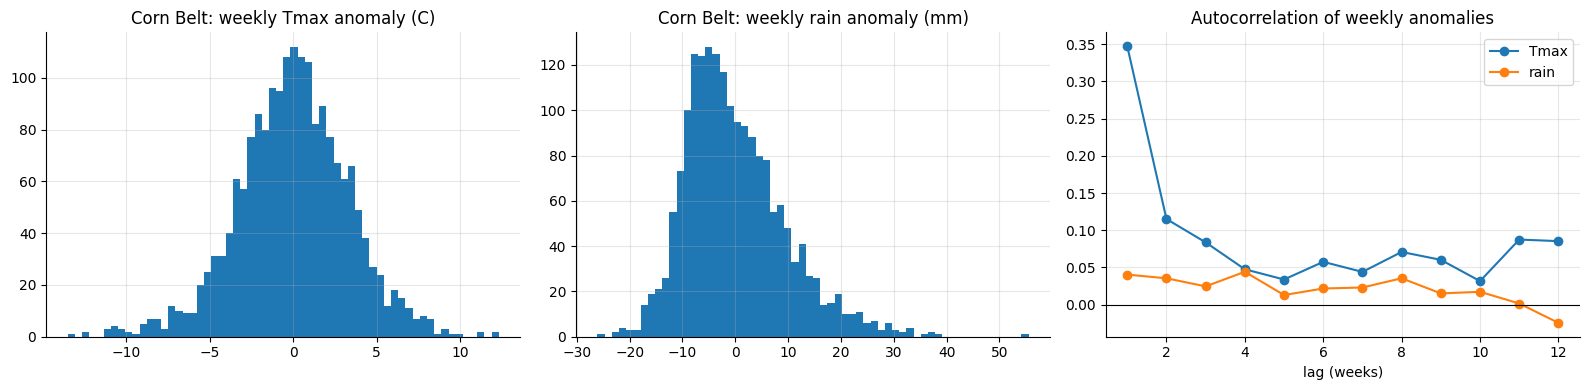

In [25]:
z = weather.loc[("corn", "US")]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
describe.weekly_anomaly(z["tmax"]).hist(bins=60, ax=axes[0]); axes[0].set_title("Corn Belt: weekly Tmax anomaly (C)")
describe.weekly_anomaly(z["precip"]).hist(bins=60, ax=axes[1]); axes[1].set_title("Corn Belt: weekly rain anomaly (mm)")
for var, label in [("tmax", "Tmax"), ("precip", "rain")]:
    axes[2].plot(describe.acf(describe.weekly_anomaly(z[var]), 12), marker="o", label=label)
axes[2].axhline(0, color="black", lw=0.8); axes[2].set_title("Autocorrelation of weekly anomalies"); axes[2].set_xlabel("lag (weeks)")
axes[2].legend(); fig.tight_layout(); plt.show()

**Reading.** Rain anomalies are right-skewed in every zone, temperature anomalies are close to
symmetric. Temperature anomalies persist (weekly autocorrelation from 0.14 in Argentina to 0.69 in
Colombia, highest in the tropics where the weather changes slowly), rain anomalies much less
(below 0.06 in the US, up to 0.3 in tropical zones). This persistence is what makes
a weekly weather signal potentially informative for the following week.

### 3.4 Trends

Land areas have warmed by about 0.3 C per decade since the 1980s, faster in Europe and Eastern Europe
(IPCC AR6). A trend of that size should appear in our temperatures.

In [26]:
rows = {}
for com, zone in zones:
    annual = weather.loc[(com, zone)].groupby(lambda d: d.year).mean().loc[1990:2025]
    rows[(com, zone)] = {"tmax (C / decade)": describe.trend_per_decade(annual["tmax"]),
                         "tmin (C / decade)": describe.trend_per_decade(annual["tmin"]),
                         "rain (% / decade)": 100 * describe.trend_per_decade(annual["precip"]) / annual["precip"].mean()}
trends = pd.DataFrame(rows).T
trends

tmax (C / decade)  tmin (C / decade)  rain (% / decade)
corn      US                     0.304              0.183             -1.525
soybeans  US                     0.296              0.188             -1.208
          BRA                    0.508              0.250            -11.304
          ARG                    0.472              0.002             -4.976
wheat_srw US                     0.314              0.197              0.436
          EU                     0.598              0.326              1.002
          BLACK_SEA              0.827              0.519              0.435
wheat_hrw US                     0.428              0.064             -2.900
coffee    BRA                    0.395              0.277            -11.050
          COL                    0.112             -0.050             -7.779
cocoa     WAF                    0.370              0.104              3.605
sugar     BRA                    0.407              0.216            -10.959
          IND                    0.061              0.080              6.512
          THA                    0.214              0.233              5.056
natgas    US                     0.287              0.175             -1.969

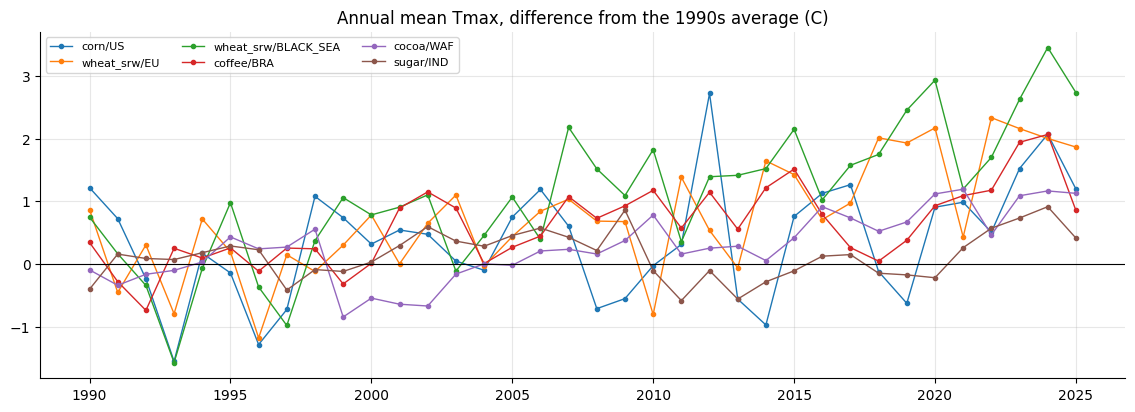

In [27]:
fig, ax = plt.subplots(figsize=(14, 4.5))
for com, zone in [("corn", "US"), ("wheat_srw", "EU"), ("wheat_srw", "BLACK_SEA"), ("coffee", "BRA"), ("cocoa", "WAF"), ("sugar", "IND")]:
    annual = weather.loc[(com, zone), "tmax"].groupby(lambda d: d.year).mean().loc[1990:2025]
    ax.plot(annual - annual.loc[1990:1999].mean(), marker="o", ms=3, lw=1, label=f"{com}/{zone}")
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Annual mean Tmax, difference from the 1990s average (C)"); ax.legend(ncol=3, fontsize=8); plt.show()

**Reading.** Tmax rises in every zone, weakly in India and Colombia (0.06 and 0.11 C per decade), with about 0.3 C per decade
in the US, 0.4 to 0.5 C in Brazil and Argentina, 0.6 C in Western Europe and 0.8 C in the Black Sea
region: the same ranking as the IPCC. This trend is the reason the stress anomalies are measured
against a climatology that moves with time (past years only), not against a fixed one.
Rainfall trends are the suspicious part: -11 % per decade in central Brazil (see 3.7).

### 3.5 Known extreme events

If the data and the weights are right, the well-documented weather shocks should be among the most
extreme seasons of the 36 years. Rank 1 = most extreme year in the expected direction.

In [28]:
describe.check_events(weather)

,series,year,value,sample mean,rank,n years
event,,,,,,
US Corn Belt drought and heat 2012,corn/US edd,2012,287.446,138.708,1.000,36
US Corn Belt drought 2012 (rain),corn/US precip,2012,192.107,305.479,1.000,36
US Midwest flood 1993,corn/US precip,1993,466.405,305.479,1.000,36
US polar vortex winter 2013-14,natgas/US hdd,2014,1988.351,1638.997,1.000,35
US warm El Nino winter 2015-16,natgas/US hdd,2016,1384.943,1638.997,1.000,35
Russian heat wave 2010,wheat_srw/BLACK_SEA tmax,2010,32.243,28.078,1.000,36
European heat wave 2003,wheat_srw/EU tmax,2003,26.381,24.018,1.000,36
Argentine drought 2022-23,soybeans/ARG precip,2023,318.469,489.019,2.000,36
Argentine drought 2017-18,soybeans/ARG precip,2018,276.961,489.019,1.000,36


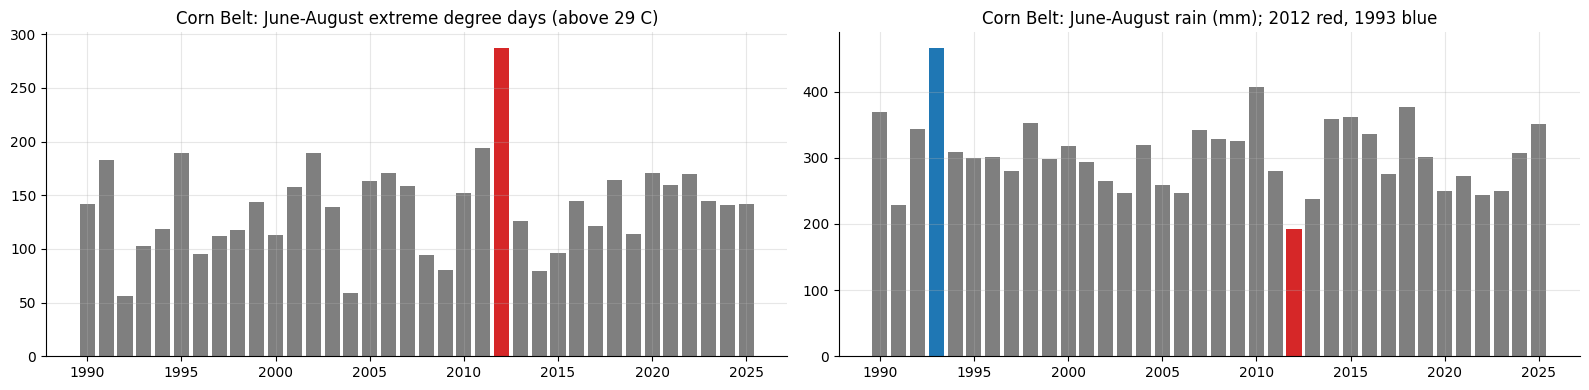

In [29]:
z = weather.loc[("corn", "US")]
edd = describe.seasonal_value(z["edd"], [6, 7, 8])
rain = describe.seasonal_value(z["precip"], [6, 7, 8])
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].bar(edd.index, edd, color=["tab:red" if y == 2012 else "tab:gray" for y in edd.index])
axes[0].set_title("Corn Belt: June-August extreme degree days (above 29 C)")
axes[1].bar(rain.index, rain, color=["tab:red" if y == 2012 else "tab:blue" if y == 1993 else "tab:gray" for y in rain.index])
axes[1].set_title("Corn Belt: June-August rain (mm); 2012 red, 1993 blue")
fig.tight_layout(); plt.show()

**Reading.** 11 of 13 events are the most extreme or second most extreme year: the 2012 US drought
(both the hottest and the driest summer), the 1993 flood, the 2013-14 polar vortex winter and the
2015-16 warm winter, the 2010 Russian heat wave, the 2003 European heat wave, the 2018 and 2023
Argentine droughts, the 2002 monsoon failure, the 2023 West African rains.

Two misses, and one event the weekly data cannot see:

* **Brazil coffee drought 2013-14**: rank 5. The years ranked above it are mostly after 2014,
  which points to the 2006 break below.
* **Indian monsoon 2009**: rank 11 (-10 %), while the all-India deficit was -22 %. The sugarcane
  weights look at Uttar Pradesh and Maharashtra, not all of India, and CPC has few Indian stations.
* **Arabica frost of 20 July 2021** (not in the table, checked on the daily grid): the coldest cell
  reaches -2 C, but only 6 % of the arabica weight goes below 2 C that day, so the zone average
  (10.5 C) barely moves. Frost is a local event that a production-weighted average dilutes:
  for frost, the **share of production below a threshold** is the right measure, not the average.

### 3.6 External check: El Nino

ENSO is the main source of year-to-year rainfall swings in the tropics, with signs documented
since Ropelewski and Halpert (1987). The ONI is an independent dataset (ocean temperatures), so finding
the right signs is a strong test of our rainfall data.

In [30]:
describe.enso_table(weather, oni)

,expected sign,corr,n years
teleconnection,,,
India monsoon (Jun-Sep): El Nino -> dry,-1,-0.422,36
Thailand (Jun-Sep): El Nino -> dry,-1,-0.410,36
Colombia (Dec-Feb): El Nino -> dry,-1,-0.594,35
Argentina (Nov-Jan): El Nino -> wet,1,0.657,35
US southern Plains (Dec-Feb): El Nino -> wet,1,0.473,35
Central Brazil (Dec-Feb): weak link,0,0.111,35
West Africa (Jun-Aug): weak link,0,-0.162,36


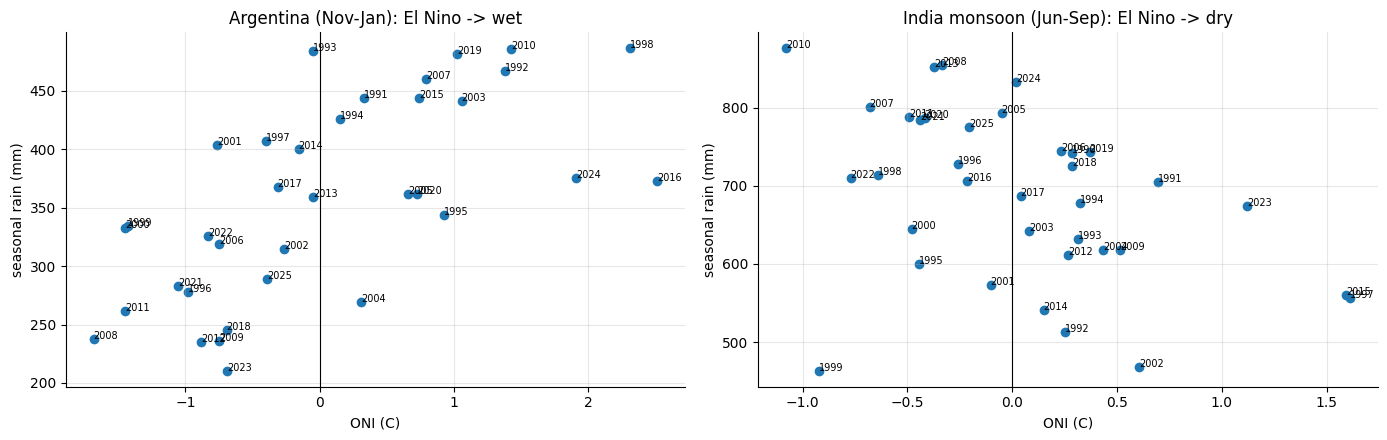

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (label, com, zone, months, cross, sign) in zip(axes, [describe.ENSO_TESTS[3], describe.ENSO_TESTS[0]]):
    rain = describe.seasonal_value(weather.loc[(com, zone), "precip"], months, "sum", cross)
    nino = describe.seasonal_value(oni, months, "mean", cross)
    both = pd.concat([rain, nino], axis=1, keys=["rain", "oni"]).dropna()
    ax.scatter(both["oni"], both["rain"])
    for year, row in both.iterrows():
        ax.annotate(str(year), (row["oni"], row["rain"]), fontsize=7)
    ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("ONI (C)"); ax.set_ylabel("seasonal rain (mm)")
    ax.set_title(label)
fig.tight_layout(); plt.show()

**Reading.** All five documented teleconnections have the right sign and are strong (|corr| 0.4 to 0.66
over 35 years); the two zones with no documented link (central Brazil, West Africa) show weak correlations.
This is independent evidence that the rainfall data and the weights measure real climate signals.

### 3.7 Rainfall decline in South America: climate or data?

Mean weekly rainfall before and after 2006 (the year CPC changes its station network), per zone. (The t-statistic uses weekly data, which are autocorrelated, so it overstates
significance; it is only an order of magnitude.)

In [32]:
breaks = describe.break_table(weather)
breaks.loc[[f"{c}/{z}" for c, z in zones]]

,before,after,change %,t-stat
corn/US,16.463,16.618,0.944,0.356
soybeans/US,17.783,17.964,1.022,0.401
soybeans/BRA,32.041,26.241,-18.101,-10.584
soybeans/ARG,19.419,17.760,-8.541,-2.344
wheat_srw/US,20.364,21.034,3.291,1.149
wheat_srw/EU,12.289,12.803,4.185,1.498
wheat_srw/BLACK_SEA,10.174,9.913,-2.563,-0.912
wheat_hrw/US,12.103,11.577,-4.349,-1.178
coffee/BRA,25.951,21.292,-17.951,-6.774
coffee/COL,37.544,30.953,-17.555,-8.182


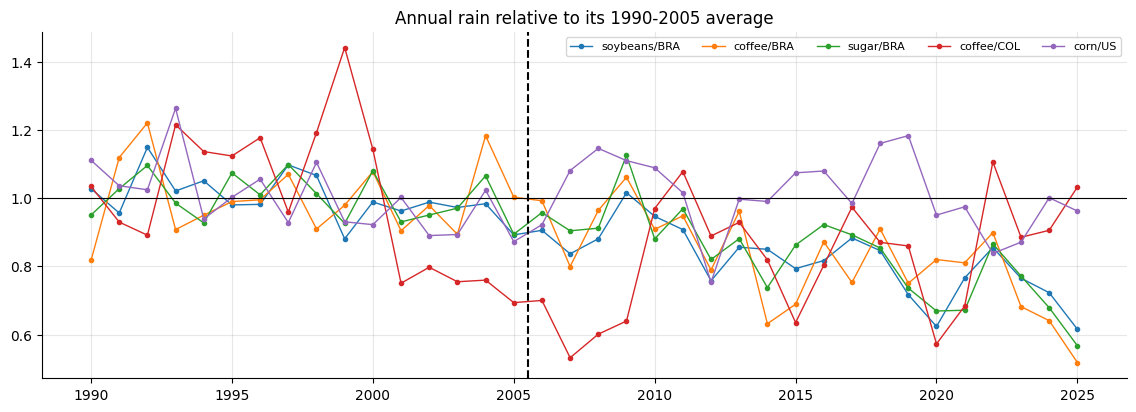

In [33]:
fig, ax = plt.subplots(figsize=(14, 4.5))
for com, zone in [("soybeans", "BRA"), ("coffee", "BRA"), ("sugar", "BRA"), ("coffee", "COL"), ("corn", "US")]:
    annual = weather.loc[(com, zone), "precip"].groupby(lambda d: d.year).sum().loc[1990:2025]
    ax.plot(annual / annual.loc[1990:2005].mean(), marker="o", ms=3, lw=1, label=f"{com}/{zone}")
ax.axvline(2005.5, color="black", ls="--"); ax.axhline(1, color="black", lw=0.8)
ax.set_title("Annual rain relative to its 1990-2005 average"); ax.legend(ncol=5, fontsize=8); plt.show()

**Reading.** Rain is 17 to 18 % lower after 2006 in the four South American tropical zones (Brazilian
soybeans, coffee, cane, Colombian coffee), while the US, Europe and the Black Sea do not move.
India (+15 %) and West Africa (+7 %) move the other way.

The plot shows that it is **not a step in 2006**: Brazilian rain declines gradually from about 2012 and
ends 35 to 45 % below its 1990-2005 level in 2024-2025; Colombian rain drops as early as 2001-2008, then recovers.
Part of this is real: central Brazil had severe droughts in 2014-15, 2019-21 and 2023-24. But a 40 % fall of
average rainfall over three large zones is far beyond published estimates of the drying trend, so a
progressive loss of reporting stations in the real-time CPC data is a likely contributor. We cannot separate
the two with CPC alone.

Consequence for the project: with anomalies measured against past years only, recent weeks in Brazil and
Colombia would look abnormally dry almost all the time. Before building rainfall anomalies there, compare with
an independent dataset (CHIRPS, satellite plus stations, from 1981, 0.05 degree), or use a rolling climatology
short enough to absorb a slow drift.

## 4. Summary

| # | Stylized fact | Reference | In our data? |
|---|---|---|---|
| 1 | Fat tails, normality rejected | Cont (2001) | Yes: daily excess kurtosis 1.4 to 4.2, JB p = 0 |
| 2 | Positive skew of commodity returns | Deaton and Laroque (1992) | Partly: mixed signs daily, positive for coffee and cocoa monthly |
| 3 | Aggregational Gaussianity | Cont (2001) | Yes: kurtosis falls with the horizon |
| 4 | Gas most volatile, grains 25 to 30 % | | Yes: gas 55 %, grains 23 to 32 % |
| 5 | No autocorrelation of returns | Cont (2001) | Yes: \|acf1\| below 0.06 |
| 6 | Volatility clustering | Cont (2001) | Yes: acf of \|r\| 0.08 to 0.16, slow decay |
| 7 | Grain volatility peaks in June-July | Anderson (1985) | Yes: corn 33 % in July vs 20 % in February |
| 8 | Gas volatility peaks in winter | EIA; Suenaga et al. (2008) | Yes: 63 to 67 % in Dec-Feb vs 45 % in spring |
| 9 | Coffee volatility in frost season | | Yes: July is the most volatile month |
| 10 | Inverse leverage effect | Carpantier (2010) | Yes for coffee, gas, wheats; neutral for others |
| 11 | Grains correlated, other groups independent | Gorton and Rouwenhorst (2006) | Yes |
| 12 | Correlation peak around 2008-2010 | Tang and Xiong (2012) | Yes: 0.13 before 2007, 0.44 in 2009 |
| 13 | Production zones match official statistics | USDA, FAOSTAT | Yes, with wheat class and robusta caveats |
| 14 | Climate regimes (monsoon, two rainy seasons, dry Brazilian winter) | | Yes |
| 15 | Rain right-skewed, temperature persistent | | Yes |
| 16 | Warming about 0.3 C per decade, faster in Europe | IPCC AR6 | Yes |
| 17 | Known extreme events are extreme in the data | | 11 of 13 ranked 1 or 2 |
| 18 | ENSO teleconnections | Ropelewski and Halpert (1987) | Yes: 5 of 5 right sign |

**Data problems found**

1. Expiry-day prints in the Yahoo continuous series: fixed (expiry-day returns dropped).
2. Rainfall in Brazil falls 35 to 45 % below its 1990s level by 2024-25 (Colombia drops in 2001-08): partly real
   droughts, probably partly a loss of CPC stations. To check against CHIRPS before building rainfall anomalies.
3. Local frost is diluted by the zone average: frost should be measured as a share of production below a threshold.
4. MapSPAM mixes wheat classes and gives Espirito Santo a large share of arabica.
5. CPC is weak over tropical Africa and India (NOAA's own warning; 2009 monsoon under-detected).

**References**

* Anderson, R. (1985). Some determinants of the volatility of futures prices. *Journal of Futures Markets*.
* Carpantier, J.-F. (2010). Commodities inventory effect. CORE discussion paper.
* Cont, R. (2001). Empirical properties of asset returns: stylized facts and statistical issues. *Quantitative Finance*.
* Deaton, A. and Laroque, G. (1992). On the behaviour of commodity prices. *Review of Economic Studies*.
* Erb, C. and Harvey, C. (2006). The strategic and tactical value of commodity futures. *Financial Analysts Journal*.
* Fackler, P. (1986). Futures price volatility: modeling non-constant variance. AAEA.
* Gorton, G. and Rouwenhorst, G. (2006). Facts and fantasies about commodity futures. *Financial Analysts Journal*.
* Ropelewski, C. and Halpert, M. (1987). Global and regional scale precipitation patterns associated with ENSO. *Monthly Weather Review*.
* Schlenker, W. and Roberts, M. (2009). Nonlinear temperature effects indicate severe damages to US crop yields. *PNAS*.
* Suenaga, H., Smith, A. and Williams, J. (2008). Volatility dynamics of NYMEX natural gas futures prices. *Journal of Futures Markets*.
* Tang, K. and Xiong, W. (2012). Index investment and the financialization of commodities. *Financial Analysts Journal*.